# 위고비 보험사 종합영향

약제비 특약 손익과 특약 때문에 추가로 치료를 시작한 가입자의 기존 보험금 변화를 결합한다. 시장 저확산→고확산은 참고 결과이며, 특약 도입효과는 같은 기준시장의 **특약 없음 `A`와 특약 있음 `A+B`**로 비교한다.

## 1. 분석 목적

최종 지표는 `약제비 특약 NPV + 기존 보험금 절감액`이다. 담보별 보험금 변화는 `특약 있음 PV - 특약 없음 PV`이며, 음수이면 보험사에 유리하다.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

def find_repo_root(start):
    for path in (start, *start.parents):
        if (path / 'config/insurer_total_impact.json').exists():
            return path
    raise FileNotFoundError('저장소 루트를 찾지 못했습니다.')

ROOT = find_repo_root(Path.cwd().resolve())
OUT = ROOT / 'outputs/insurer_total_impact'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
required = [
    'representative_product_summary.csv', 'coverage_scenario_results.csv',
    'eight_product_results.csv', 'benefit_amount_sensitivity.csv',
    'representative_start_paths.csv', 'validation.json'
]
missing = [name for name in required if not (OUT / name).exists()]
if missing:
    raise FileNotFoundError('결과 파일이 없습니다: ' + ', '.join(missing) +
                            '\n저장소 루트에서 python -m models.impact.insurer_total_impact 를 실행하세요.')

for candidate in ['AppleGothic', 'Arial Unicode MS', 'Malgun Gothic', 'NanumGothic']:
    try:
        font_manager.findfont(candidate, fallback_to_default=False)
        plt.rcParams['font.family'] = candidate
        break
    except ValueError:
        continue
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

representative = pd.read_csv(OUT / 'representative_product_summary.csv').iloc[0]
coverage = pd.read_csv(OUT / 'coverage_scenario_results.csv')
products = pd.read_csv(OUT / 'eight_product_results.csv')
sensitivity = pd.read_csv(OUT / 'benefit_amount_sensitivity.csv')
paths = pd.read_csv(OUT / 'representative_start_paths.csv')
validation = json.loads((OUT / 'validation.json').read_text(encoding='utf-8'))
assert validation['status'] == 'PASS'
assert len(coverage) == 3 and len(products) == 24
print(f'저장소: {ROOT}')
print(f"검증: {validation['status']} · 8개 상품 × 3개 보유율")

저장소: /Users/dapanman/Desktop/glp1_pricing_analysis
검증: PASS · 8개 상품 × 3개 보유율


## 2. 공통 분석집단과 대표 상품

SELECT 유사 임상위험을 적용한 62세 가상 가입자 1,000건을 대상으로 한다. 특약 현금흐름은 남성 72%·여성 28%로 가중하며, 대표 상품은 10만 원·13회·90일, 목표이익률 10%의 확정 보험료를 고정한다.

In [2]:
cohort_table = pd.DataFrame({
    '항목': ['대표 연령', '성별 구성', '최초 계약', '보험기간', '대표 상품', '고정 월보험료'],
    '설정': ['62세', '남 72% · 여 28%', '1,000건', '10년', '10만 원 · 13회 · 90일', f"{representative['fixed_monthly_premium_krw']:,.0f}원"]
})
display(cohort_table)

,항목,설정
0,대표 연령,62세
1,성별 구성,남 72% · 여 28%
2,최초 계약,"1,000건"
3,보험기간,10년
4,대표 상품,10만 원 · 13회 · 90일
5,고정 월보험료,"3,141원"


## 3. 담보 보유율 시나리오

사망보장은 보험연구원 2018 조사, 심장·뇌·질병수술 담보는 한화손해보험 공개 표본의 관찰범위를 단순화했다. 실제 특정 보험사의 보유율 추정치가 아닌 공개자료 기반 대리 포트폴리오다.

In [3]:
holding = coverage.set_index('coverage_scenario_name_ko')[[
    'death_holding_rate', 'mi_holding_rate', 'stroke_holding_rate', 'gallbladder_holding_rate'
]].rename(columns={
    'death_holding_rate': '사망', 'mi_holding_rate': '심근경색',
    'stroke_holding_rate': '뇌졸중', 'gallbladder_holding_rate': '담낭절제술'
})
display(holding.style.format('{:.1%}'))

,사망,심근경색,뇌졸중,담낭절제술
coverage_scenario_name_ko,,,,
낮음,15.0%,30.0%,30.0%,20.0%
기준,21.4%,40.0%,40.0%,25.0%
높음,30.6%,50.0%,50.0%,40.0%


## 4. 특약 없음·있음 치료경로

상품조건으로 다시 생성한 같은 기준 시작률에서 `A`와 `A+B`를 비교한다. 두 경로에는 동일한 지속·중단·재개 모형을 적용한다.

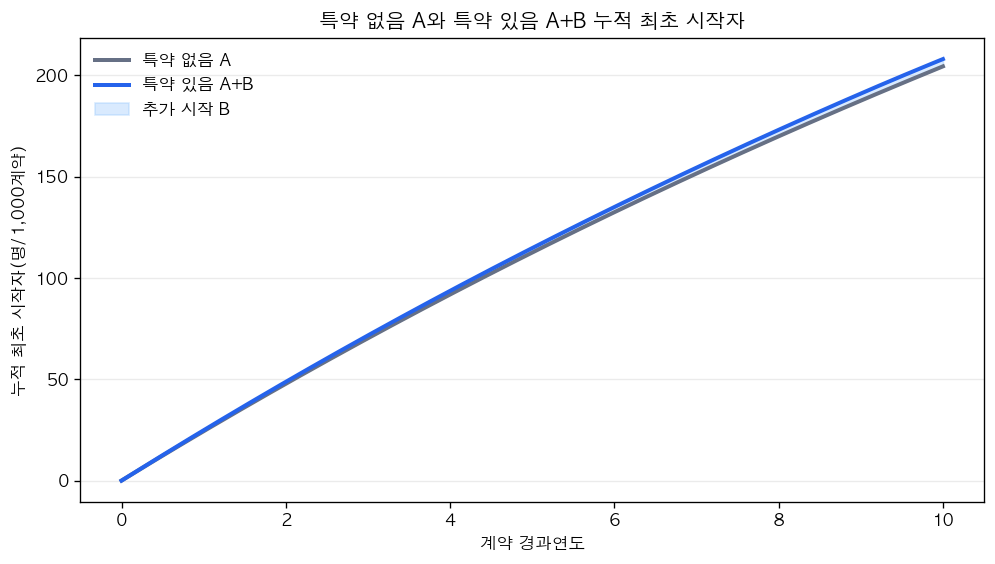

10년 추가 시작자 B: 3.60명


In [4]:
fig, ax = plt.subplots(figsize=(8.4, 4.8))
x = paths['elapsed_day'] / 365.25
ax.plot(x, paths['without_rider_A_cumulative_first_starts'], label='특약 없음 A', lw=2.4, color='#667085')
ax.plot(x, paths['with_rider_A_plus_B_cumulative_first_starts'], label='특약 있음 A+B', lw=2.4, color='#2563EB')
ax.fill_between(x, paths['without_rider_A_cumulative_first_starts'], paths['with_rider_A_plus_B_cumulative_first_starts'], color='#93C5FD', alpha=.35, label='추가 시작 B')
ax.set(title='특약 없음 A와 특약 있음 A+B 누적 최초 시작자', xlabel='계약 경과연도', ylabel='누적 최초 시작자(명/1,000계약)')
ax.grid(axis='y', alpha=.25); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / '01_A_vs_AplusB_cumulative_starts.png', dpi=300, facecolor='white')
plt.show()
print(f"10년 추가 시작자 B: {representative['additional_first_starts_B']:.2f}명")

## 5. 약제비 특약 손익

현재 판매 후보의 목표이익률 10% 확정 보험료를 그대로 적용한다. 62세 남녀 혼합 코호트에서의 손익은 가격산출 시점의 49세 여성 회귀검증값과 구분한다.

In [5]:
rider_table = pd.DataFrame({
    '항목': ['보험료 수입 PV', '약제비 급부 PV', '사업비 PV', '반환금 PV', '특약 NPV'],
    '금액(백만원)': [representative['rider_premium_income_pv_krw'], representative['rider_benefit_pv_krw'], representative['rider_expenses_pv_krw'], representative['rider_refund_pv_krw'], representative['rider_npv_krw']]
})
rider_table['금액(백만원)'] /= 1e6
display(rider_table.style.format({'금액(백만원)': '{:,.2f}'}))

,항목,금액(백만원)
0,보험료 수입 PV,305.09
1,약제비 급부 PV,194.65
2,사업비 PV,79.87
3,반환금 PV,0.18
4,특약 NPV,30.39


## 6. 담보별 기존 보험금 변화

기준 보유율에서 사망·심근경색·뇌졸중은 보험사에 유리한 감소, 담낭절제술은 불리한 증가 방향이다.

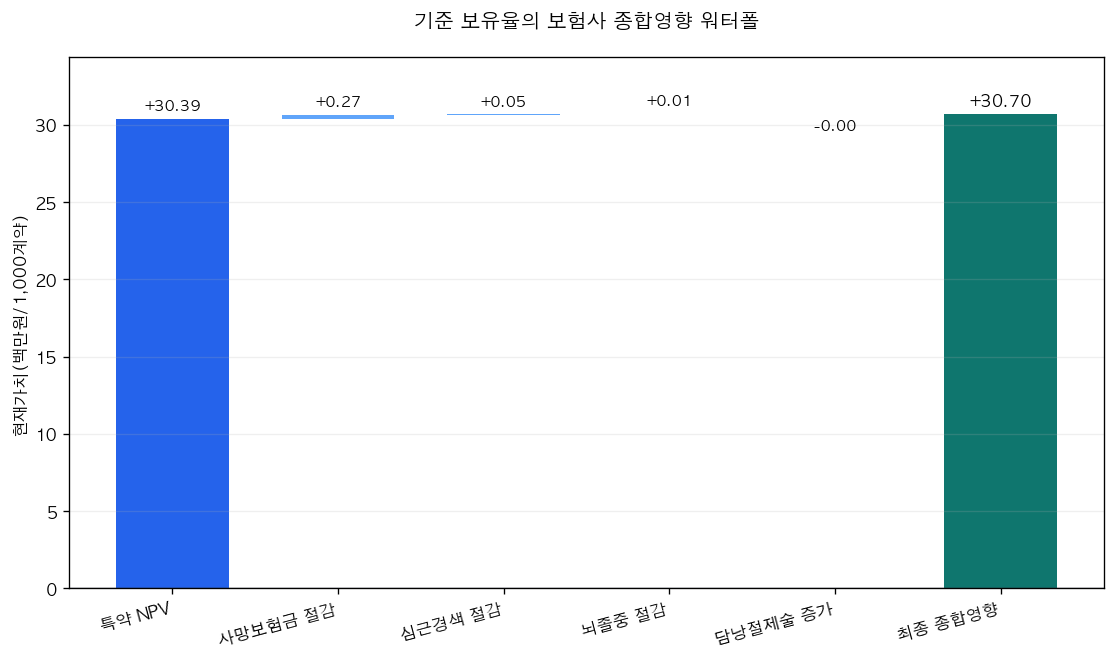

In [6]:
base = coverage.loc[coverage['coverage_scenario_id'].eq('base')].iloc[0]
labels = ['특약 NPV', '사망보험금 절감', '심근경색 절감', '뇌졸중 절감', '담낭절제술 증가']
values = np.array([base['rider_npv_krw'], base['death_existing_claims_adjustment_krw'], base['mi_existing_claims_adjustment_krw'], base['stroke_existing_claims_adjustment_krw'], base['gallbladder_existing_claims_adjustment_krw']]) / 1e6
starts = np.r_[0, np.cumsum(values)[:-1]]
total = values.sum()
fig, ax = plt.subplots(figsize=(9.4, 5.6))
colors = ['#2563EB'] + ['#60A5FA' if v >= 0 else '#F97316' for v in values[1:]]
ax.bar(np.arange(5), values, bottom=starts, color=colors, width=.68)
ax.bar(5, total, color='#0F766E', width=.68)
for i, (s, v) in enumerate(zip(starts, values)):
    ax.text(i, s + v + (0.35 if v >= 0 else -0.35), f'{v:+.2f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
ax.text(5, total + .35, f'{total:+.2f}', ha='center', va='bottom', fontweight='bold')
ax.axhline(0, color='#344054', lw=.8); ax.set_xticks(range(6), labels + ['최종 종합영향'], rotation=15, ha='right')
ax.set_ylim(0, total * 1.12)
ax.set_title('기준 보유율의 보험사 종합영향 워터폴', pad=18)
ax.set_ylabel('현재가치(백만원/1,000계약)')
ax.grid(axis='y', alpha=.2); fig.tight_layout()
fig.savefig(FIG / '02_base_coverage_waterfall.png', dpi=300, facecolor='white'); plt.show()

## 7. 보유율 적용 후 보험사 종합영향

보유율이 높아질수록 기존 보험금 절감액은 커진다. 약제비 특약 NPV는 보유율과 무관하게 고정된다.

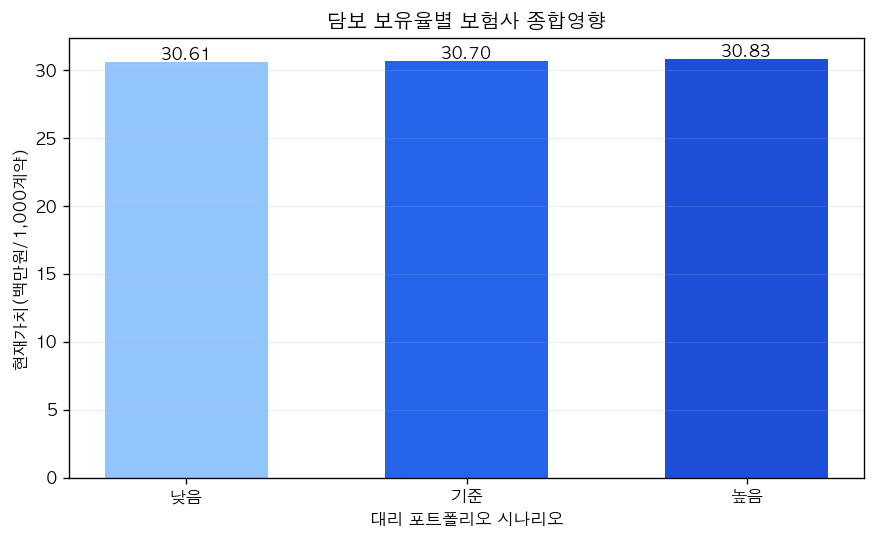

,coverage_scenario_name_ko,rider_npv_krw,existing_claims_adjustment_krw,insurer_total_impact_krw
0,낮음,"30,387,623","224,004","30,611,627"
1,기준,"30,387,623","316,185","30,703,808"
2,높음,"30,387,623","442,216","30,829,838"


In [7]:
order = ['low', 'base', 'high']
plot_cov = coverage.set_index('coverage_scenario_id').loc[order].reset_index()
fig, ax = plt.subplots(figsize=(7.4, 4.6))
y = plot_cov['insurer_total_impact_krw'] / 1e6
bars = ax.bar(plot_cov['coverage_scenario_name_ko'], y, color=['#93C5FD', '#2563EB', '#1D4ED8'], width=.58)
for bar, value in zip(bars, y): ax.text(bar.get_x()+bar.get_width()/2, value+.12, f'{value:.2f}', ha='center', fontweight='bold')
ax.set(title='담보 보유율별 보험사 종합영향', xlabel='대리 포트폴리오 시나리오', ylabel='현재가치(백만원/1,000계약)')
ax.grid(axis='y', alpha=.2); fig.tight_layout()
fig.savefig(FIG / '03_coverage_scenario_range.png', dpi=300, facecolor='white'); plt.show()
display(plot_cov[['coverage_scenario_name_ko','rider_npv_krw','existing_claims_adjustment_krw','insurer_total_impact_krw']].style.format({c:'{:,.0f}' for c in ['rider_npv_krw','existing_claims_adjustment_krw','insurer_total_impact_krw']}))

## 8. 8개 상품 비교

각 상품은 해당 조건의 `A+B` 시작률을 다시 생성하고 기존 10% 확정 보험료를 고정했다. 셀 값은 1,000계약 기준 종합영향 NPV다.

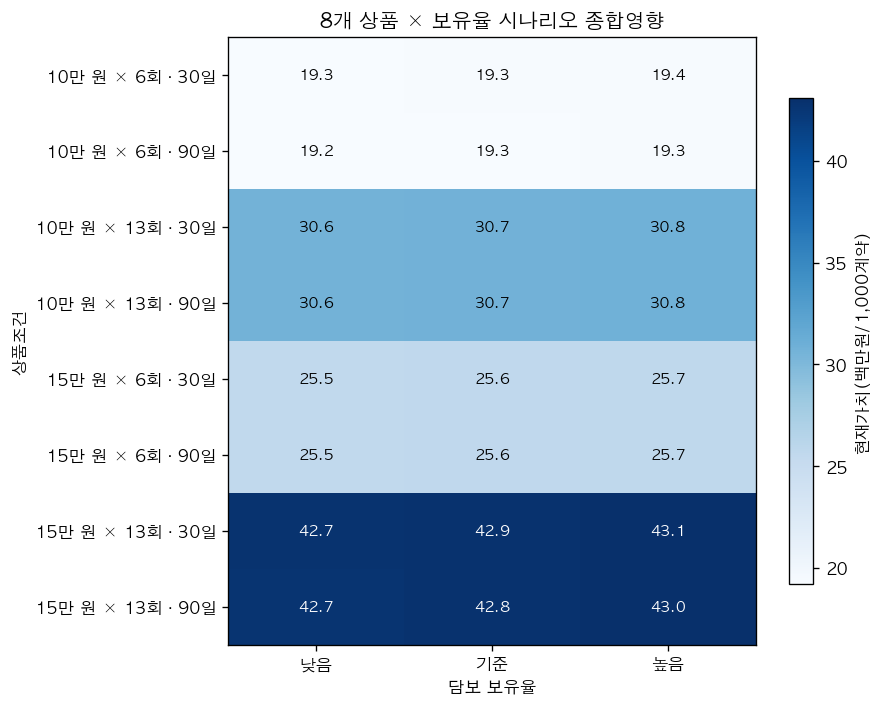

In [8]:
products = products.copy()
products['상품'] = products.apply(lambda r: f"{r['benefit_per_dispense_krw']/10000:.0f}만 원 × {int(r['max_claims'])}회 · {int(r['waiting_days'])}일", axis=1)
product_order = products.drop_duplicates('product_id').sort_values(['benefit_per_dispense_krw','max_claims','waiting_days'])['상품'].tolist()
matrix = products.pivot(index='상품', columns='coverage_scenario_name_ko', values='insurer_total_impact_krw').loc[product_order, ['낮음','기준','높음']] / 1e6
fig, ax = plt.subplots(figsize=(7.6, 6.0))
im = ax.imshow(matrix, cmap='Blues', aspect='auto')
ax.set_xticks(range(3), matrix.columns); ax.set_yticks(range(8), matrix.index)
threshold = (matrix.to_numpy().min() + matrix.to_numpy().max()) / 2
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix.iloc[i, j]
        ax.text(j, i, f'{value:.1f}', ha='center', va='center', color='white' if value > threshold else 'black', fontsize=9)
ax.set(title='8개 상품 × 보유율 시나리오 종합영향', xlabel='담보 보유율', ylabel='상품조건')
cbar = fig.colorbar(im, ax=ax, shrink=.8); cbar.set_label('현재가치(백만원/1,000계약)')
fig.tight_layout(); fig.savefig(FIG / '04_eight_products_coverage_heatmap.png', dpi=300, facecolor='white'); plt.show()

## 9. 가입금액 민감도

대표 상품에만 가입금액 0.5·1.0·1.5배를 적용했다. 가입금액 배수는 기존 보험금 조정액에만 선형 적용하며 약제비 특약 NPV는 바꾸지 않는다.

In [9]:
display(sensitivity.pivot(index='benefit_amount_multiplier', columns='coverage_scenario_name_ko', values='insurer_total_impact_krw').style.format('{:,.0f}'))

coverage_scenario_name_ko,기준,낮음,높음
benefit_amount_multiplier,,,
0.500000,"30,545,715","30,499,625","30,608,731"
1.000000,"30,703,808","30,611,627","30,829,838"
1.500000,"30,861,900","30,723,629","31,050,946"


## 10. 시장 확산효과와 특약 기여효과

시장 저확산→고확산은 별도 참고값이다. 이를 특약 손익에 더하지 않고, 특약 도입의 `A→A+B` 기여효과와 나란히 비교한다.

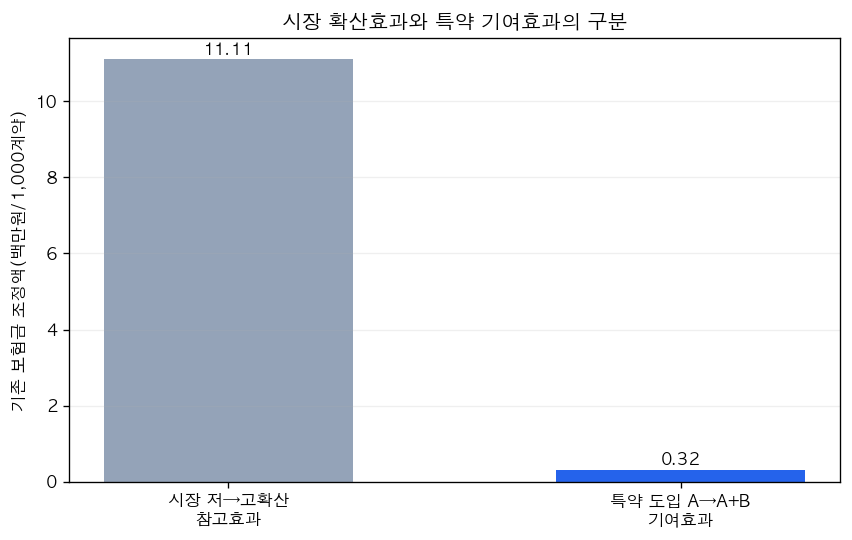

In [10]:
comparison = pd.Series({
    '시장 저→고확산\n참고효과': base['market_expansion_reference_adjustment_krw'] / 1e6,
    '특약 도입 A→A+B\n기여효과': base['existing_claims_adjustment_krw'] / 1e6
})
fig, ax = plt.subplots(figsize=(7.2, 4.6))
bars = ax.bar(comparison.index, comparison.values, color=['#94A3B8','#2563EB'], width=.55)
for bar, value in zip(bars, comparison.values): ax.text(bar.get_x()+bar.get_width()/2, value+.12, f'{value:.2f}', ha='center', fontweight='bold')
ax.set(title='시장 확산효과와 특약 기여효과의 구분', ylabel='기존 보험금 조정액(백만원/1,000계약)')
ax.grid(axis='y', alpha=.2); fig.tight_layout()
fig.savefig(FIG / '05_market_vs_rider_contribution.png', dpi=300, facecolor='white'); plt.show()

## 해석과 한계

- 결과는 실제 특정 보험사의 포트폴리오가 아니라 공개자료 기반 대리 보유율과 SELECT 집계 임상위험을 적용한 연구용 기대손익 NPV다.
- 기존 담보 보유 여부와 사건위험은 독립으로 가정했다. 담보 간 상관, 손실분포와 요구자본은 반영하지 않았다.
- 보험료 자체의 추가 행동반응, 세금, 자본비용, 준비금, 투자손익과 IFRS17 보험계약마진은 제외했다.
- 시장 확산효과는 참고 결과이고, 최종 특약 종합영향에는 `A→A+B`만 포함했다.